# Stabilizer 状態 → Graph 状態 + Clifford の導出

`stab_to_graph.py` の使い方デモ。

任意の stabilizer 状態 $|\psi\rangle$ は、あるグラフ $G$ の graph 状態 $|G\rangle$ と局所 Clifford 演算 $C$ を用いて $|\psi\rangle = C|G\rangle$ と表せる (arXiv:2603.17743, Section II)。
ここでは Stim の graph-state 合成機能を使ってこの $(G, C)$ を導出し、得られた回路が元の stabilizer 状態を正しく再現することを検証する。

In [1]:
# ! pip install -r requirements.txt

In [2]:
import sys
sys.path.insert(0, ".")

import networkx as nx
import matplotlib.pyplot as plt

from stab_to_graph import stabilizers_to_graph_state, verify_equivalence, verify_equivalence_qiskit

## 例1: 5量子ビット符号 $[\![5,1,3]\!]$ の $|0\rangle_L$

In [3]:
stabilizers_5q = ["XZZXI", "IXZZX", "XIXZZ", "ZXIXZ", "ZZZZZ"]

decomp = stabilizers_to_graph_state(stabilizers_5q)
print("Graph edges:", sorted(decomp.graph.edges()))
print("\nLocal Clifford circuit C:")
print(decomp.local_clifford_circuit)
print("\nFull preparation circuit:")
print(decomp.preparation_circuit)

print("\nEquivalence check (Stim):", verify_equivalence(stabilizers_5q, decomp.preparation_circuit))
print("Equivalence check (Qiskit):", verify_equivalence_qiskit(stabilizers_5q, decomp.preparation_circuit))

Graph edges: [(0, 2), (0, 3), (0, 4), (1, 2), (1, 4), (2, 3), (2, 4)]

Local Clifford circuit C:
X 2
Z 0 4
H 2

Full preparation circuit:
RX 0 1 2 3 4
TICK
CZ 0 2 0 3 0 4 1 2 1 4 2 3 2 4
TICK
X 2
Z 0 4
H 2

Equivalence check (Stim): True


Equivalence check (Qiskit): True


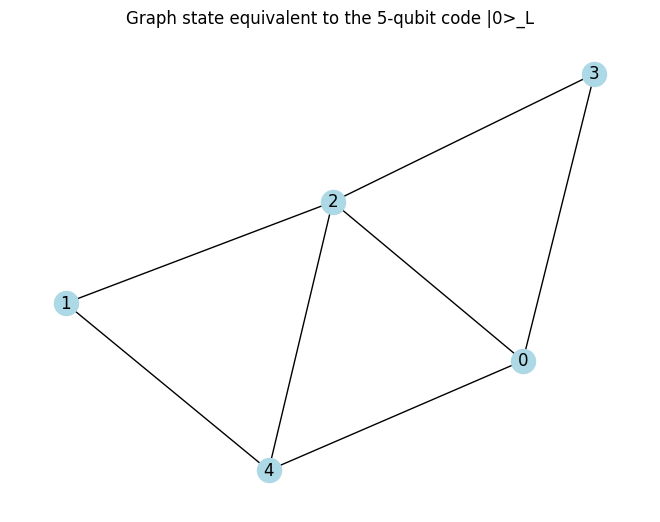

In [4]:
nx.draw(decomp.graph, with_labels=True, node_color="lightblue")
plt.title("Graph state equivalent to the 5-qubit code |0>_L")
plt.show()

## 例2: Steane 符号 $[\![7,1,3]\!]$ の $|0\rangle_L$

In [5]:
steane_x = ["IIIXXXX", "IXXIIXX", "XIXIXIX"]
steane_z = ["IIIZZZZ", "IZZIIZZ", "ZIZIZIZ"]
logical_z = "ZZZZZZZ"
stabilizers_7q = steane_x + steane_z + [logical_z]

decomp7 = stabilizers_to_graph_state(stabilizers_7q)
print("Graph edges:", sorted(decomp7.graph.edges()))
print("Equivalence check (Stim):", verify_equivalence(stabilizers_7q, decomp7.preparation_circuit))
print("Equivalence check (Qiskit):", verify_equivalence_qiskit(stabilizers_7q, decomp7.preparation_circuit))

Graph edges: [(0, 1), (0, 2), (1, 4), (1, 5), (2, 4), (2, 6), (3, 4), (3, 5), (3, 6)]
Equivalence check (Stim): True
Equivalence check (Qiskit): True


## Qiskit によるクロスチェック

上記の等価性検証は Stim (`peek_observable_expectation`) だけに依存している。実装のバグが Stim 側のバグに起因する可能性を排除するため、独立したライブラリである Qiskit (`qiskit.quantum_info.StabilizerState`) でも同じ検証を行う (`verify_equivalence_qiskit`)。

注意点として、Pauli 文字列の量子ビット順序規約が Stim (左端が qubit 0) と Qiskit (little-endian、右端が qubit 0) で逆になる。非対称なランダム stabilizer 状態で試すと、この反転を行わない場合に検証が失敗することが確認できる。

In [6]:
import stim

# 非対称なランダム stabilizer 状態でも一致することを確認
for n in [1, 2, 3, 6, 10]:
    t = stim.Tableau.random(n)
    stabs = t.to_stabilizers()
    d = stabilizers_to_graph_state(stabs)
    print(f"n={n}: graph edges={sorted(d.graph.edges())}")
    ok_stim = verify_equivalence(stabs, d.preparation_circuit)
    ok_qiskit = verify_equivalence_qiskit(stabs, d.preparation_circuit)
    print(f"n={n}: stim={ok_stim} qiskit={ok_qiskit}")

n=1: graph edges=[]
n=1: stim=True qiskit=True
n=2: graph edges=[(0, 1)]
n=2: stim=True qiskit=True
n=3: graph edges=[(0, 1), (1, 2)]
n=3: stim=True qiskit=True
n=6: graph edges=[(0, 2), (0, 5), (1, 2), (1, 3), (2, 3), (2, 5)]
n=6: stim=True qiskit=True
n=10: graph edges=[(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 8), (1, 2), (1, 5), (1, 6), (1, 9), (2, 3), (2, 6), (2, 7), (2, 8), (3, 4), (3, 6), (3, 7), (4, 5), (4, 6), (4, 8), (4, 9), (5, 6), (6, 7), (7, 8), (7, 9), (8, 9)]
n=10: stim=True qiskit=True


# 論文Table II に出てくる符号のグラフ状態導出

`qec_codes.py` に、論文 Table I の符号のうち出典を確認できたもの (8/14) を [MQT QECC](https://github.com/munich-quantum-toolkit/qecc) 経由でまとめてある。残り6つ ([[36,8,6]], [[40,20,6]] (non-CSS), [[42,12,5]], [[48,6,8]], [[64,12,8]], [[80,8,10]]) は論文中に引用がなく、厳密な check 行列の出典を確認できなかったため未対応 (詳細は README 参照)。

In [7]:
from qec_codes import CODES, UNAVAILABLE_TABLE_ROWS, get_stabilizers

print("対応済み:", list(CODES.keys()))
print("未対応:", UNAVAILABLE_TABLE_ROWS)

対応済み: ['surface_9_1_3', 'carbon_12_2_4', 'reed_muller_15_1_3', 'hamming_15_7_3', 'color_17_1_5', 'color_19_1_5', 'golay_23_1_7', 'gross_144_12_12']
未対応: ['[[36,8,6]]', '[[40,20,6]] (non-CSS)', '[[42,12,5]]', '[[48,6,8]]', '[[64,12,8]]', '[[80,8,10]]']


In [8]:
for key, meta in CODES.items():
    stabilizers = get_stabilizers(key)
    decomp = stabilizers_to_graph_state(stabilizers)
    ok_stim = verify_equivalence(stabilizers, decomp.preparation_circuit)
    ok_qiskit = verify_equivalence_qiskit(stabilizers, decomp.preparation_circuit)
    print(
        f"{meta['table_row']:14s} {meta['name']:35s} n={meta['n']:>4} "
        f"edges={decomp.graph.number_of_edges():>4} stim_ok={ok_stim} qiskit_ok={ok_qiskit}"
    )

[[9,1,3]]      Surface code                        n=   9 edges=  10 stim_ok=True qiskit_ok=True
[[12,2,4]]     Carbon code                         n=  12 edges=  27 stim_ok=True qiskit_ok=True
[[15,1,3]]     Reed-Muller code                    n=  15 edges=  31 stim_ok=True qiskit_ok=True
[[15,7,3]]     Hamming code                        n=  15 edges=  49 stim_ok=True qiskit_ok=True
[[17,1,5]]     Color code (4.8.8, square-octagon)  n=  17 edges=  39 stim_ok=True qiskit_ok=True
[[19,1,5]]     Color code (hexagonal)              n=  19 edges=  51 stim_ok=True qiskit_ok=True
[[23,1,7]]     Golay code                          n=  23 edges=  77 stim_ok=True qiskit_ok=True


[[144,12,12]]  Gross code                          n= 144 edges=3142 stim_ok=True qiskit_ok=True


### Golay 符号 $[\![23,1,7]\!]$ のグラフを可視化

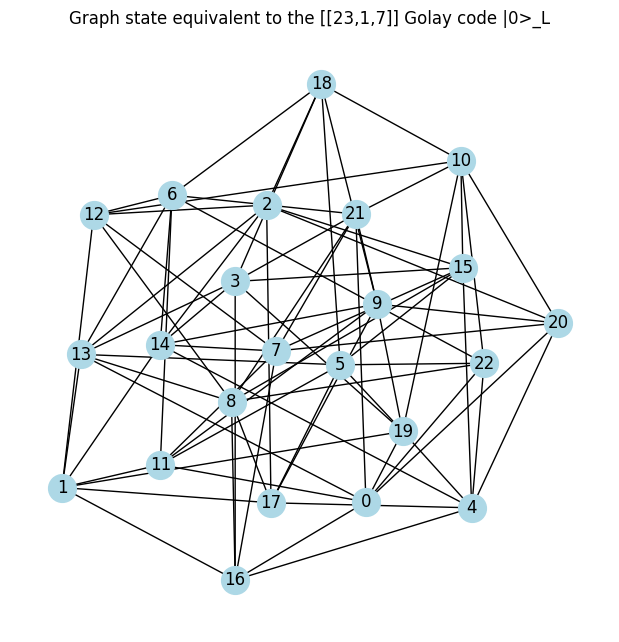

In [9]:
golay_stabilizers = get_stabilizers("golay_23_1_7")
golay_decomp = stabilizers_to_graph_state(golay_stabilizers)

plt.figure(figsize=(6, 6))
nx.draw(golay_decomp.graph, with_labels=True, node_color="lightblue", node_size=400)
plt.title("Graph state equivalent to the [[23,1,7]] Golay code |0>_L")
plt.show()

# `ldpc` / `bposd` の符号を試す

[quantumgizmos/ldpc](https://github.com/quantumgizmos/ldpc) は古典・量子 LDPC 符号のデコーダを提供するライブラリ。CSS 符号を組み立てるクラスは姉妹パッケージの [`bposd`](https://github.com/quantumgizmos/bp_osd) にある (`pip install bposd` で `ldpc` も付随してインストールされる):

- `ldpc.codes`: 種符号となる古典符号 (`hamming_code`, `rep_code`, `ring_code`) のパリティ検査行列を生成
- `bposd.css.css_code(hx, hz)`: 任意の Hx, Hz から CSS 符号 (次元・論理演算子 `lx`, `lz` を自動計算) を構成
- `bposd.hgp.hgp(h1, h2)`: 2つの古典符号の hypergraph product から量子 LDPC 符号 (surface/toric 符号など) を構成

これらの Hx, Hz, `lz` から stabilizer 生成子の Pauli 文字列を組み立てるヘルパー `css_code_stabilizers` を定義し、`stabilizers_to_graph_state` に渡す。`independent_rows_gf2` / `pauli_strings_from_binary_rows` は `qec_codes.py` で CSS 符号を扱うのに使ったのと同じ関数 (hypergraph product の check 行列は冗長な行を含みうるため)。

In [10]:
import numpy as np
from ldpc.codes import hamming_code, rep_code, ring_code
from bposd.css import css_code
from bposd.hgp import hgp

from stab_to_graph import independent_rows_gf2, pauli_strings_from_binary_rows


def css_code_stabilizers(code: css_code) -> list[str]:
    """|0>_L stabilizer generators (independent X-checks + independent Z-checks +
    logical Z operators) for a bposd `css_code` / `hgp` object."""
    n = code.N
    hx, hz, lz = np.atleast_2d(code.hx), np.atleast_2d(code.hz), np.atleast_2d(code.lz)
    x_checks = pauli_strings_from_binary_rows(hx[independent_rows_gf2(hx)], "X", n)
    z_checks = pauli_strings_from_binary_rows(hz[independent_rows_gf2(hz)], "Z", n)
    logicals = pauli_strings_from_binary_rows(lz, "Z", n)
    stabilizers = x_checks + z_checks + logicals
    assert len(stabilizers) == n, f"got {len(stabilizers)} generators for n={n}"
    return stabilizers

## `css_code` / `hgp` から作った符号を一括で試す

Hamming 符号から作った Steane 符号 (`css_code`)、反復符号/リング符号を種にした hypergraph product (surface 符号, toric 符号、および非対称な組み合わせ) をまとめて `stabilizers_to_graph_state` にかける。

In [11]:
seed_codes = {
    "rep_3": rep_code(3),
    "rep_4": rep_code(4),
    "ring_3": ring_code(3),
    "ring_4": ring_code(4),
}

ldpc_examples = {
    "Steane (Hamming(3))": css_code(hx=hamming_code(3), hz=hamming_code(3), code_distance=3),
    "Surface (rep_3 x rep_3)": hgp(seed_codes["rep_3"], seed_codes["rep_3"], compute_distance=True),
    "Surface (rep_4 x rep_4)": hgp(seed_codes["rep_4"], seed_codes["rep_4"], compute_distance=True),
    "Toric (ring_3 x ring_3)": hgp(seed_codes["ring_3"], seed_codes["ring_3"], compute_distance=True),
    "Toric (ring_4 x ring_4)": hgp(seed_codes["ring_4"], seed_codes["ring_4"], compute_distance=True),
    "HGP (rep_3 x ring_4)": hgp(seed_codes["rep_3"], seed_codes["ring_4"], compute_distance=True),
}

ldpc_decomps = {}
for name, code in ldpc_examples.items():
    stabilizers = css_code_stabilizers(code)
    decomp = stabilizers_to_graph_state(stabilizers)
    ldpc_decomps[name] = decomp
    ok_stim = verify_equivalence(stabilizers, decomp.preparation_circuit)
    ok_qiskit = verify_equivalence_qiskit(stabilizers, decomp.preparation_circuit)
    print(
        f"{name:26s} [[{code.N},{code.K}]] "
        f"edges={decomp.graph.number_of_edges():>4} stim_ok={ok_stim} qiskit_ok={ok_qiskit}"
    )

Steane (Hamming(3))        [[7,1]] edges=   9 stim_ok=True qiskit_ok=True
Surface (rep_3 x rep_3)    [[13,1]] edges=  18 stim_ok=True qiskit_ok=True
Surface (rep_4 x rep_4)    [[25,1]] edges=  48 stim_ok=True qiskit_ok=True
Toric (ring_3 x ring_3)    [[18,2]] edges=  34 stim_ok=True qiskit_ok=True


Toric (ring_4 x ring_4)    [[32,2]] edges=  91 stim_ok=True qiskit_ok=True
HGP (rep_3 x ring_4)       [[20,1]] edges=  32 stim_ok=True qiskit_ok=True


### Surface 符号 (rep_3 x rep_3) のグラフを可視化

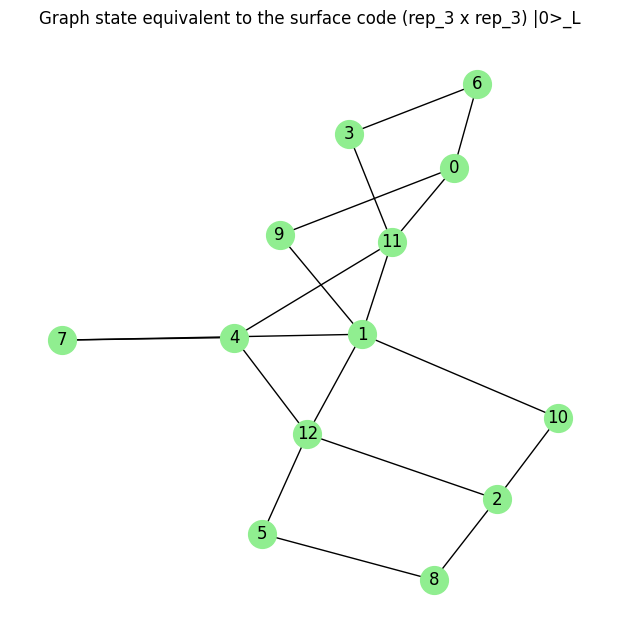

In [12]:
surface_decomp = ldpc_decomps["Surface (rep_3 x rep_3)"]

plt.figure(figsize=(6, 6))
nx.draw(surface_decomp.graph, with_labels=True, node_color="lightgreen", node_size=400)
plt.title("Graph state equivalent to the surface code (rep_3 x rep_3) |0>_L")
plt.show()

### 使用可能な符号

`ldpc_examples` に登録した符号と、そのパラメータ・グラフ辺数の一覧。`seed_codes` (`rep_code` / `ring_code` の距離) や `hamming_code` の引数を変えれば、同じ枠組みで別の距離・別の種符号の組み合わせを試せる。

In [13]:
print(f"{'name':26s} {'[[N,K,D]]':14s} {'edges':>6s}")
for name, code in ldpc_examples.items():
    params = f"[[{code.N},{code.K},{code.D}]]"
    edges = ldpc_decomps[name].graph.number_of_edges()
    print(f"{name:26s} {params:14s} {edges:>6}")

name                       [[N,K,D]]       edges
Steane (Hamming(3))        [[7,1,3]]           9
Surface (rep_3 x rep_3)    [[13,1,3]]         18
Surface (rep_4 x rep_4)    [[25,1,4]]         48
Toric (ring_3 x ring_3)    [[18,2,3]]         34
Toric (ring_4 x ring_4)    [[32,2,4]]         91
HGP (rep_3 x ring_4)       [[20,1,3]]         32


# インスタンスサイズの異なる表面符号


上の `hgp` の例と同様に、`rep_code(d)` 同士の hypergraph product から符号距離 $d$ の表面符号 $[\![2d^2-2d+1,\,1,\,d]\!]$ を構成し、各インスタンスサイズ (符号距離) について対応する graph 状態を導出する。

In [14]:
distances = [3, 4, 5, 6, 7]

surface_codes_by_d = {d: hgp(rep_code(d), rep_code(d), compute_distance=True) for d in distances}

surface_decomps_by_d = {}
for d, code in surface_codes_by_d.items():
    stabilizers = css_code_stabilizers(code)
    decomp = stabilizers_to_graph_state(stabilizers)
    surface_decomps_by_d[d] = decomp
    ok_stim = verify_equivalence(stabilizers, decomp.preparation_circuit)
    ok_qiskit = verify_equivalence_qiskit(stabilizers, decomp.preparation_circuit)
    print(
        f"d={d}: [[{code.N},{code.K},{code.D}]] "
        f"edges={decomp.graph.number_of_edges():>5} stim_ok={ok_stim} qiskit_ok={ok_qiskit}"
    )

d=3: [[13,1,3]] edges=   18 stim_ok=True qiskit_ok=True
d=4: [[25,1,4]] edges=   48 stim_ok=True qiskit_ok=True
d=5: [[41,1,5]] edges=  100 stim_ok=True qiskit_ok=True
d=6: [[61,1,6]] edges=  180 stim_ok=True qiskit_ok=True


d=7: [[85,1,7]] edges=  294 stim_ok=True qiskit_ok=True


### 各符号距離のグラフ状態を可視化

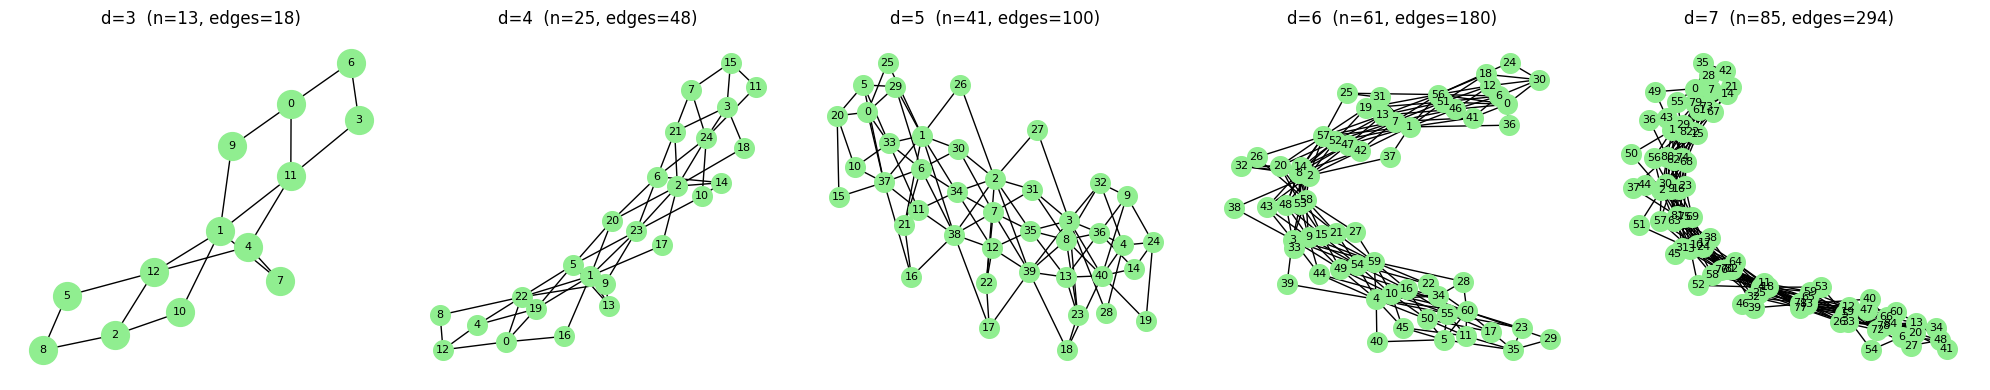

In [15]:
fig, axes = plt.subplots(1, len(distances), figsize=(4 * len(distances), 4))
for ax, d in zip(axes, distances):
    decomp = surface_decomps_by_d[d]
    nx.draw(
        decomp.graph,
        ax=ax,
        with_labels=True,
        node_color="lightgreen",
        node_size=200 if decomp.graph.number_of_nodes() > 20 else 400,
        font_size=8,
    )
    ax.set_title(f"d={d}  (n={surface_codes_by_d[d].N}, edges={decomp.graph.number_of_edges()})")
plt.tight_layout()
plt.show()

### インスタンスサイズ (符号距離) とグラフ辺数の関係

  d [[N,K,D]]       edges
  3 [[13,1,3]]         18
  4 [[25,1,4]]         48
  5 [[41,1,5]]        100
  6 [[61,1,6]]        180
  7 [[85,1,7]]        294


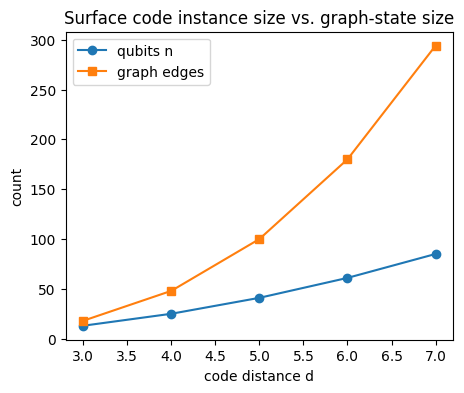

In [16]:
print(f"{'d':>3s} {'[[N,K,D]]':14s} {'edges':>6s}")
for d, code in surface_codes_by_d.items():
    params = f"[[{code.N},{code.K},{code.D}]]"
    edges = surface_decomps_by_d[d].graph.number_of_edges()
    print(f"{d:>3d} {params:14s} {edges:>6}")

plt.figure(figsize=(5, 4))
n_list = [surface_codes_by_d[d].N for d in distances]
edge_list = [surface_decomps_by_d[d].graph.number_of_edges() for d in distances]
plt.plot(distances, n_list, "o-", label="qubits n")
plt.plot(distances, edge_list, "s-", label="graph edges")
plt.xlabel("code distance d")
plt.ylabel("count")
plt.title("Surface code instance size vs. graph-state size")
plt.legend()
plt.show()